In [1]:
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.data.datasets import register_coco_instances
# from detectron2.utils.logger import setup_logger
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader
import matplotlib.pyplot as plt
import cv2
import os
import random

count = 0

c:\Users\Natalia\anaconda3\envs\pyqt6\lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


#### Import and register evaluation dataset

In [2]:
count +=1 

path_dataset_eval = 'C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images'

dataset_eval_name = "my_dataset_val_" + str(count)

# dataset name, json path, images path
register_coco_instances(dataset_eval_name, {}, path_dataset_eval  + "/instances_val.json", path_dataset_eval) 

nuts_metadata_val = MetadataCatalog.get(dataset_eval_name)

dataset_dicts_val = DatasetCatalog.get(dataset_eval_name)



Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.



#### Visualise evaluation dataset

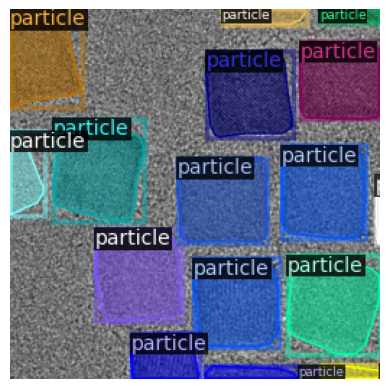

In [3]:
number_of_training_imgs_to_visualise = 1

for d in random.sample(dataset_dicts_val, number_of_training_imgs_to_visualise):

    img = cv2.imread(d["file_name"])

    visualizer = Visualizer(img[:, :, ::-1], metadata=nuts_metadata_val, scale=0.5)

    vis = visualizer.draw_dataset_dict(d)

    final_image = vis.get_image()[:, :, ::-1]

    plt.imshow(final_image, cmap='gray')
    
    plt.axis("off")

#### Select model path and get configs to load the model

In [7]:
model_path = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMapp\\models\\model_final_mary-scott-training2.pth"
device = 'cpu'
number_of_classes = 1
iou_thresh = 0.8

In [8]:
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml"))
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.DEVICE = device
cfg.MODEL.WEIGHTS = model_path
cfg.SOLVER.IMS_PER_BATCH = 1  # This is the real "batch size" commonly known to deep learning people
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 1024   # The "RoIHead batch size".
cfg.MODEL.ROI_HEADS.NUM_CLASSES = number_of_classes
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = iou_thresh

#### Create predictor

In [6]:
predictor = DefaultPredictor(cfg)

AssertionError: Torch not compiled with CUDA enabled

#### Check Prediction results

c:\Users\Natalia\anaconda3\envs\pyqt6\lib\site-packages\torch\functional.py:539: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:3638.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


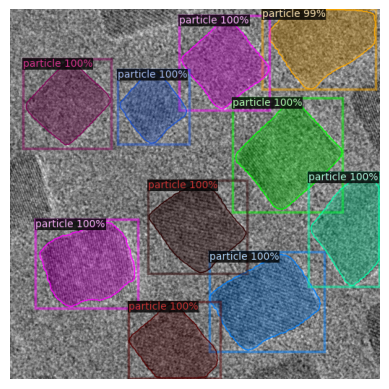

In [ ]:
for d in random.sample(dataset_dicts_val, 1):

    img = cv2.imread(d["file_name"])

    _, tail = os.path.split(d["file_name"])

    outputs = predictor(img)  # format is documented at https://detectron2.readthedocs.io/tutorials/models.html#model-output-format
    
    v = Visualizer(img[:, :, ::-1],
                metadata=nuts_metadata_val,
                scale=1,
                instance_mode=ColorMode.IMAGE_BW   # remove the colors of unsegmented pixels. This option is only available for segmentation models
    )
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
    
    final_image = out.get_image()[:, :, ::-1]

    plt.imshow(final_image, cmap='gray')

    plt.axis("off")

#### Evaluate model

In [11]:
evaluator = COCOEvaluator(dataset_eval_name, output_dir="./output")

val_loader = build_detection_test_loader(cfg, dataset_eval_name)

inference_on_dataset(predictor.model, val_loader, evaluator)


Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.



KeyboardInterrupt: 